<a href="https://colab.research.google.com/github/89P13Peder/89P13Peder.github.io/blob/main/AircraftClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tf_keras

In [ ]:
!unzip Comerciales/aviones_comerciales.zip -d Comerciales

Archive:  Comerciales/aviones_comerciales.zip
   creating: Comerciales/aviones_comerciales/
  inflating: Comerciales/aviones_comerciales/000527021.png  
  inflating: Comerciales/aviones_comerciales/09e1b4f1-c261-45d9-a3ca-7f7ba091d1b9_16-9-discover-aspect-ratio_default_0.jpg  
  inflating: Comerciales/aviones_comerciales/101024_SL_Blog_Aviones_Carga_Mas_Grandes.jpg  
  inflating: Comerciales/aviones_comerciales/11-1024x538.jpg  
  inflating: Comerciales/aviones_comerciales/118-4312095.jpg  
  inflating: Comerciales/aviones_comerciales/1200px-Pan_Am_Boeing_747-121_N732PA_Bidini.jpg  
  inflating: Comerciales/aviones_comerciales/120232.jpeg  
  inflating: Comerciales/aviones_comerciales/120235.jpeg  
  inflating: Comerciales/aviones_comerciales/1920_a350-emirates-a.jpg  
  inflating: Comerciales/aviones_comerciales/2474-que-tipos-de-aviones-existen-y-como-puedes-aprender-a-distinguirlos.jpg  
  inflating: Comerciales/aviones_comerciales/250px-Airbus_A320-2142C_Airbus_Industrie_JP7617615.

In [ ]:
!rm -rf Comerciales/aviones_comerciales.zip

In [ ]:
!unzip Combate/aviones_combate.zip -d Combate

Archive:  Combate/aviones_combate.zip
   creating: Combate/aviones_combate/
  inflating: Combate/aviones_combate/018-025_CAPA-Gripen_282-11140px.jpg  
  inflating: Combate/aviones_combate/1000w_q75-2.jpg  
  inflating: Combate/aviones_combate/1067310025_0030002400_600x0_80_0_1_769fe9fbce770ac03df4bb998b992de0.jpg  
  inflating: Combate/aviones_combate/110319214115_sp_aviones_tornado.jpg.webp  
  inflating: Combate/aviones_combate/1134025777_512025602048_1400x0_80_0_0_2f0321203d8500614053f07d3f69e277.jpg  
  inflating: Combate/aviones_combate/1200px-Lockheed_Martin_F-22A_Raptor_JSOH.jpg  
  inflating: Combate/aviones_combate/1366_2000.jpg  
  inflating: Combate/aviones_combate/1366_20002.jpeg  
  inflating: Combate/aviones_combate/1366_521.jpeg  
  inflating: Combate/aviones_combate/1536x864_cmsv2_a61f9850-4845-55bb-a734-9dc8d6969261-9332034.jpg  
  inflating: Combate/aviones_combate/160402954_735511084003937_498197770155245660_n.jpg  
  inflating: Combate/aviones_combate/1604871376_f-x

In [ ]:
!rm -rf Combate/aviones_combate.zip

In [ ]:
!mkdir dataset
!cp -r Comerciales dataset/Comerciales
!cp -r Combate dataset/Combate

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=10,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

In [ ]:
data_gen_entrenamiento = datagen.flow_from_directory("/content/dataset",
                                                     target_size=(224,224),
                                                     batch_size=32, shuffle=True,
                                                     subset="training")
data_gen_pruebas = datagen.flow_from_directory("/content/dataset",
                                               target_size=(224,224),
                                               batch_size=32, shuffle = True,
                                               subset = "validation")

Found 522 images belonging to 2 classes.
Found 130 images belonging to 2 classes.


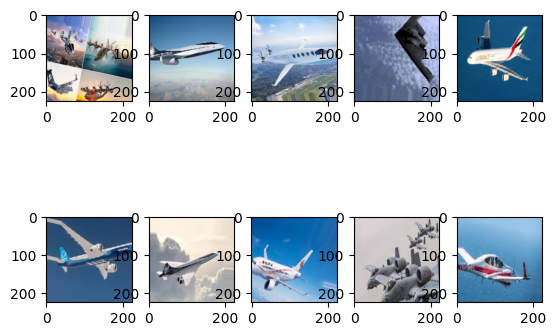

In [ ]:
import matplotlib.pyplot as plt
for imagen, etiqueta in data_gen_entrenamiento:
  for i in range(10):
    plt.subplot(2,5, i+1)
    plt.imshow(imagen[i])
  break
plt.show()

In [ ]:
import tensorflow as tf
import tf_keras as tfk
import tensorflow_hub as hub

# Cargar el modelo preentrenado desde TensorFlow Hub
url = "https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4"
feature_extractor_layer = hub.KerasLayer(url, input_shape=(224, 224, 3))
feature_extractor_layer.trainable = True


In [ ]:
modelo = tfk.Sequential([
    feature_extractor_layer,
    #tfk.layers.Dense(128, activation='relu'),
    #tfk.layers.Dropout(0.3),
    tfk.layers.Dense(2, activation='softmax')
])

In [ ]:
modelo.compile(
    optimizer=tfk.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)

In [ ]:
EPOCAS = 20
steps_per_epoch = data_gen_entrenamiento.samples // data_gen_entrenamiento.batch_size
validation_steps = data_gen_pruebas.samples // data_gen_pruebas.batch_size

entrenamiento = modelo.fit(
    data_gen_entrenamiento,
    epochs=EPOCAS,
    steps_per_epoch=steps_per_epoch,
    validation_data=data_gen_pruebas,
    validation_steps=validation_steps
)

Epoch 1/20
16/16 [==============================] - ETA: 0s - loss: 0.4924 - accuracy: 0.8102

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


16/16 [==============================] - 40s 832ms/step - loss: 0.4924 - accuracy: 0.8102 - val_loss: 0.4064 - val_accuracy: 0.8516
Epoch 2/20
16/16 [==============================] - 12s 815ms/step - loss: 0.2173 - accuracy: 0.9512 - val_loss: 0.3430 - val_accuracy: 0.8828
Epoch 3/20
16/16 [==============================] - 11s 757ms/step - loss: 0.1565 - accuracy: 0.9776 - val_loss: 0.2659 - val_accuracy: 0.9375
Epoch 4/20
16/16 [==============================] - 10s 687ms/step - loss: 0.1645 - accuracy: 0.9714 - val_loss: 0.2766 - val_accuracy: 0.9062
Epoch 5/20
16/16 [==============================] - 15s 961ms/step - loss: 0.1144 - accuracy: 0.9939 - val_loss: 0.1548 - val_accuracy: 0.9688
Epoch 6/20
16/16 [==============================] - 10s 623ms/step - loss: 0.1282 - accuracy: 0.9837 - val_loss: 0.1489 - val_accuracy: 0.9609
Epoch 7/20
16/16 [==============================] - 11s 702ms/step - loss: 0.1087 - accuracy: 0.9898 - val_loss: 0.1395 - val_accuracy: 0.9766
Epoch 8/20

In [ ]:
from PIL import Image
import cv2

def categorizar(ruta):
  img = Image.open(ruta)
  img = img.convert("RGB")
  img = np.array(img).astype(float)/255

  img = cv2.resize(img,(224,224))
  prediccion = modelo.predict(img.reshape(-1,224,224,3))
  clase = np.argmax(prediccion[0], axis=-1)

  if clase == 0:
    return "Es un avión de combate."
  else:
    return "Es un avión comercial."


In [ ]:
ruta = "Combate1.jpg"
prediccion = categorizar(ruta)
print(prediccion)

1/1 [==============================] - 0s 25ms/step
Es un avión de combate.


In [ ]:
ruta = "Comercial1.jpg"
prediccion = categorizar(ruta)
print(prediccion)

1/1 [==============================] - 0s 21ms/step
Es un avión comercial.


In [ ]:
ruta = "Combate2.jpg"
prediccion = categorizar(ruta)
print(prediccion)

1/1 [==============================] - 0s 99ms/step
Es un avión de combate.


In [ ]:
ruta = "Comercial2.jpg"
prediccion = categorizar(ruta)
print(prediccion)

1/1 [==============================] - 0s 51ms/step
Es un avión comercial.
